In [1]:
import torch
import torch.nn as nn
from torch.nn import functional as F
from torchvision import datasets, transforms
import os
import matplotlib.pyplot as plt
import random

device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
print(device)

cpu


In [2]:
model_number = "06"
CHECKPOINT_PATH = f'checkpoints/model{model_number}.pt'
LOG_FILE = f'train_data/model{model_number}_data.csv'
RESUME_ITER = 0     # Default starting step
save = False    # save model and data?

# HYPERPARAMS
batch_size = 128
learning_rate = 1e-3
eval_iters = 100
estimate_loss_iters = 100

# n_neurons for each layer
layers = [256]

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(), # Converts image to PyTorch Tensor and scales to [0, 1]
    transforms.Normalize((0.5,), (0.5,)), # Shifts values to range [-1, 1] for stability
    transforms.Lambda(lambda x: torch.flatten(x))
])

# Train=True gets the 60,000 training images
train_set = datasets.MNIST(
    root='./data', 
    train=True, 
    download=True, 
    transform=transform
)

# Train=False gets the 10,000 test images (for checking accuracy later)
test_set = datasets.MNIST(
    root='./data', 
    train=False, 
    download=True, 
    transform=transform
)

In [4]:
# DEFINE GET BATCH FUNCTION
def get_batch(split, batch_size):
    """fetches a random batch of images to train on"""

    data = train_set if split == 'train' else test_set
    ix = torch.randint(len(data), (batch_size,))

    x = torch.stack([data[i][0] for i in ix])
    y = torch.tensor([data[i][1] for i in ix])
    x, y = x.to(device), y.to(device)
    return x, y

In [5]:
# DEFINE ESTIMATE LOSS FUNCTION
@torch.no_grad()
def estimate_loss():
    out = {}
    m.eval()
    for split in ['train', 'val']:
        correct_counts = 0
        total_counts = 0
        losses = torch.zeros(estimate_loss_iters)
        for k in range(estimate_loss_iters):
            X, Y = get_batch(split, batch_size)
            logits, loss = m(X, Y)
            losses[k] = loss.item()
            guesses = torch.argmax(logits, dim=1)
            correct_counts += (guesses == Y).sum().item()
            total_counts += Y.numel()
        out[split] = losses.mean()
        out[f'{split}_acc'] = (correct_counts / total_counts) * 100
    m.train()
    return out

In [6]:
# MODEL DEFINITION
class Layer(nn.Module):
    """one layer of neurons"""
    def __init__(self, in_feat, out_feat):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_feat, out_feat), 
            nn.ReLU()
        )
        
    def forward(self, x):
        return self.net(x)
        
class NN(nn.Module):
    """the neural network"""
    def __init__(self):
        super().__init__()
        self.Layers = nn.Sequential(*[Layer(784 if i == 0 else layers[i-1], l) for i, l in enumerate(layers)])      
        self.lm_head = nn.Linear(layers[-1] if layers else 784, 10)

    def forward(self, x, targets=None):
        x = self.Layers(x)
        logits = self.lm_head(x)

        if targets == None:
            loss = None
        else:
            loss = F.cross_entropy(logits, targets)
        
        return logits, loss

    def generate(self, index):
        with torch.no_grad():
            self.eval()
            logits, loss = self(index)
            self.train()
        return torch.argmax(logits, dim=1)

In [7]:
# SAVE/LOAD CHECKPOINT FUNCTIONS
def load_checkpoint(model, optimizer, path):
    """loads a previous checkpoint from the checkpoint path specified above, 
    returns the most recent optimizer step that model and optimizer were saved on"""
    checkpoint = torch.load(path)
    
    # Load the learned knowledge
    model.load_state_dict(checkpoint['model_state_dict'])
    
    # Load the learned history/momentum
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    
    # Return the iteration number to start the loop from
    return checkpoint['iteration']

def save_checkpoint(step, model, optimizer, path):
    """saves the current model and optimizer state to the checkpoint path specified at the top
    Prints to confirm completion"""
    checkpoint = {
        'iteration': step,
        # 1. Save the model's learned knowledge
        'model_state_dict': model.state_dict(),
        # 2. Save the optimizer's learned history/momentum
        'optimizer_state_dict': optimizer.state_dict()
    }

    # Save the dictionary to a single file. This overwrites the old checkpoint.
    torch.save(checkpoint, path)
    print(f"Checkpoint {step} Saved")

In [8]:
# INITIALIZE AND LOAD MODEL AND OPTIMIZER

# define the model
m = NN()
m.to(device)

# define a PyTorch optimizer
optim = torch.optim.AdamW(m.parameters(), lr=learning_rate)

if save:
    # check for an existing checkpoint and load if necessary
    if os.path.exists(CHECKPOINT_PATH):
        print(f"Loading checkpoint from {CHECKPOINT_PATH}")
        RESUME_ITER = load_checkpoint(m, optim, CHECKPOINT_PATH)
        print(f"Loaded succesfuly from step: {RESUME_ITER}")
    else:
        print(f"No checkpoint found at {CHECKPOINT_PATH}.")
        print(f"New model will be training from step: {RESUME_ITER}")

print(f"Total parameters: {sum(p.numel() for p in m.parameters()):,}")

Total parameters: 203,530


In [9]:
# How Many total steps do you want to train to?
max_iters = 2000

In [10]:
# TRAINING LOOP
losses = estimate_loss()    # estimate a base loss before training session
print(f"Step: {RESUME_ITER:04d}, Train Loss: {losses['train']:.3f}, Val Loss: {losses['val']:.3f}")
print(f"            Train Accu: {losses['train_acc']:.2f}%,Val Accu: {losses['val_acc']:.2f}%")

if save:
    # if never trained log the pre optim loss in a new csv
    if RESUME_ITER == 0:
        print(f"Initializing new data collection file at: {LOG_FILE}")
        with open(LOG_FILE, 'a') as f:
            f.write(f"step,train_loss,val_loss\n{RESUME_ITER:05d},{losses['train']:.3f},{losses['val']:.3f}\n")

for i in range(RESUME_ITER + 1, max_iters + 1):
    optim.zero_grad(set_to_none=True)
    
    xb, yb= get_batch('train', batch_size)
    logits, loss = m(xb, yb)
    loss.backward()
    optim.step()

    if (i - RESUME_ITER) % eval_iters == 0:
        print()
        losses = estimate_loss()
        
        print(f"Step: {i:04d}, Train Loss: {losses['train']:.3f}, Val Loss: {losses['val']:.3f}")
        print(f"            Train Accu: {losses['train_acc']:.2f}%,Val Accu: {losses['val_acc']:.2f}%")
        

        if save:
            save_checkpoint(i, m, optim, CHECKPOINT_PATH)
    
            # write a new line in our data csv
            with open(LOG_FILE, 'a') as f:
                f.write(f"{i:05d},{losses['train']:.3f},{losses['val']:.3f}\n")
            print(f"Step Documented")

Step: 0000, Train Loss: 2.313, Val Loss: 2.311
            Train Accu: 11.89%,Val Accu: 12.12%

Step: 0100, Train Loss: 0.414, Val Loss: 0.383
            Train Accu: 87.78%,Val Accu: 88.73%

Step: 0200, Train Loss: 0.338, Val Loss: 0.320
            Train Accu: 90.10%,Val Accu: 90.51%

Step: 0300, Train Loss: 0.326, Val Loss: 0.309
            Train Accu: 90.32%,Val Accu: 91.08%

Step: 0400, Train Loss: 0.259, Val Loss: 0.259
            Train Accu: 92.62%,Val Accu: 92.46%

Step: 0500, Train Loss: 0.220, Val Loss: 0.219
            Train Accu: 93.59%,Val Accu: 93.89%

Step: 0600, Train Loss: 0.210, Val Loss: 0.187
            Train Accu: 93.94%,Val Accu: 94.53%

Step: 0700, Train Loss: 0.192, Val Loss: 0.191
            Train Accu: 94.70%,Val Accu: 94.35%

Step: 0800, Train Loss: 0.181, Val Loss: 0.186
            Train Accu: 95.02%,Val Accu: 94.98%

Step: 0900, Train Loss: 0.154, Val Loss: 0.164
            Train Accu: 95.36%,Val Accu: 95.28%

Step: 1000, Train Loss: 0.151, Val Loss:

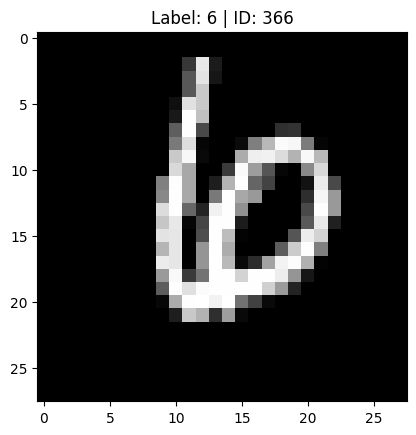

Guess: 6


In [33]:
# Generate Guess
image_id = random.randint(0, 10000)
flat_vector, label = test_set[image_id]

# Reshape it for plotting
# Matplotlib expects [Height, Width]
image_to_show = flat_vector.view(28, 28)

# Plot it
plt.imshow(image_to_show)
plt.title(f"Label: {label} | ID: {image_id}")
plt.show()

# Print Guess
print(f"Guess: {int(torch.argmax(m(flat_vector.to(device))[0]))}")